# 01 · Meeting the neighbours: the Iris problem and the KNN idea

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/KNN_IRIS_classification/blob/main/notebooks/01_the_problem_and_the_knn_idea.ipynb)

**After this notebook you will be able to** explain how a K-nearest-neighbours (KNN) classifier makes a decision, train one on the Iris flowers, and say why one accuracy number from one random split cannot be trusted.

| | |
|---|---|
| Who it is for | Anyone who knows basic Python and has seen a table of data. No machine learning needed. |
| Time | About 30 minutes to read and play; the code runs in a few seconds on a CPU. |
| Random seed | `42` everywhere (so your numbers match the ones printed here). |
| Next | `02` asks: which `k` is best, and how do we measure that fairly? |

## 1. The big question

A botanist measures a flower with a ruler: four numbers (the length and width of its sepals and petals). **Can a computer name the species from those four numbers alone?**

This matters far beyond flowers. A doctor has a few measurements of a patient, a bank has a few numbers about a customer, a camera has a few numbers about a pixel. In each case we have *labelled examples from the past* and a *new case* to label. This is called **classification**, and the Iris data set is the classic place to learn it.

## 2. Intuition first: ask your neighbours

You join a new school and nobody tells you which sport the students at your table play. How could you guess your own best sport?

You would look at the **5 students sitting closest to you** and see which sport most of them play. If 4 out of 5 play football, you guess football.

KNN does exactly this with flowers:

1. Put every known flower on a map, using its measurements as coordinates.
2. Put the new flower on the same map.
3. Find the **K** known flowers that are closest to it.
4. Let them **vote**. The most common species wins.

There is no "training" in the usual sense. The model simply *remembers* the examples. (That is why KNN is called a *lazy learner*.)

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once.
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/KNN_IRIS_classification.git"], check=True)
    os.chdir("KNN_IRIS_classification/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.iris_knn import (SEED, FEATURES, CLASSES, load_iris_frame, split_data,
                          scatter_species, plot_decision_regions, save_figure)

np.random.seed(SEED)               # fixed seed: you will get the same numbers as the author
plt.rcParams["figure.dpi"] = 100

The cell above loaded our tools. We import our own small helpers from `src/` so every notebook uses the same code.

## 3. A picture of the idea

**Predict first.** In the picture below, a new flower (black star) has petal length 4.9 cm and petal width 1.6 cm. We will draw its 5 nearest known flowers. Before you run the cell: which species do you think will win the vote?

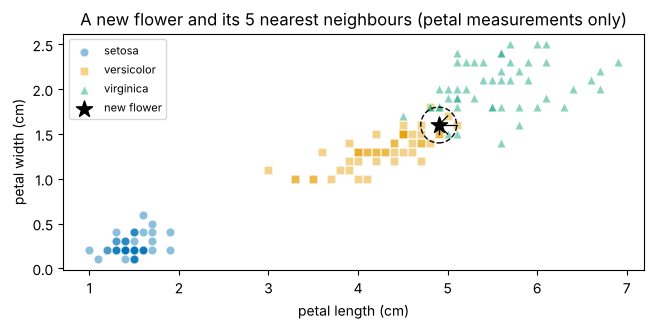

In [2]:
from sklearn.neighbors import NearestNeighbors

df = load_iris_frame()
fx, fy = "petal length (cm)", "petal width (cm)"
new_flower = pd.DataFrame({fx: [4.9], fy: [1.6]})

finder = NearestNeighbors(n_neighbors=5).fit(df[[fx, fy]])
distances, neighbour_rows = finder.kneighbors(new_flower)

fig, ax = plt.subplots(figsize=(7.5, 3.6))
scatter_species(ax, df, fx, fy, alpha=0.45)
for row in neighbour_rows[0]:
    ax.plot([4.9, df.loc[row, fx]], [1.6, df.loc[row, fy]], color="black", linewidth=0.9)
ax.add_patch(plt.Circle((4.9, 1.6), distances[0].max(), fill=False, linestyle="--", color="black"))
ax.scatter([4.9], [1.6], marker="*", s=150, color="black", label="new flower", zorder=5)
ax.set_aspect("equal")
ax.set_title("A new flower and its 5 nearest neighbours (petal measurements only)")
ax.legend(loc="upper left", fontsize=8)
save_figure(fig, "01_neighbours_idea.png")
plt.show()

*Figure 1. What to notice:* the dashed circle contains exactly the 5 closest known flowers. Its size is set by the farthest of them. Flowers outside the circle do not get a vote.

In [3]:
votes = df.loc[neighbour_rows[0], "species"].value_counts()
print(votes)
print("Winner of the vote:", votes.idxmax())

species
versicolor    4
virginica     1
Name: count, dtype: int64
Winner of the vote: versicolor


The vote is just counting. Did the winner match your prediction? Notice that the answer is not unanimous; that is exactly the kind of flower where a classifier can go wrong.

## 4. A little math (just one formula)

"Closest" needs a precise meaning. The usual choice is the **Euclidean distance**, the straight-line distance you would measure with a ruler:

$$d(a, b) = \sqrt{(a_1-b_1)^2 + (a_2-b_2)^2 + \dots + (a_n-b_n)^2}$$

- $a$ and $b$ are two flowers.
- $a_i$ and $b_i$ are their $i$-th measurements (for Iris, $i$ goes from 1 to 4).
- We subtract, square (so negatives do not cancel positives), add up, and take the square root.

With two measurements this is the Pythagorean theorem. With four it is the same idea in more dimensions.

In [4]:
first_flower = df.loc[0, FEATURES].to_numpy(dtype=float)
second_flower = df.loc[1, FEATURES].to_numpy(dtype=float)

print("flower 0:", first_flower)
print("flower 1:", second_flower)
print("differences:", np.round(first_flower - second_flower, 2))
print("distance by the formula :", np.sqrt(np.sum((first_flower - second_flower) ** 2)))
print("distance by numpy       :", np.linalg.norm(first_flower - second_flower))

flower 0: [5.1 3.5 1.4 0.2]
flower 1: [4.9 3.  1.4 0.2]
differences: [0.2 0.5 0.  0. ]
distance by the formula : 0.5385164807134502
distance by numpy       : 0.5385164807134502


Both lines print the same number, so the formula and the library agree. A small distance means the two flowers look alike.

## 5. Meet the data

The file `data/iris.data` comes from the UCI Machine Learning Repository and goes back to R. A. Fisher (1936). **Predict first:** how many flowers do you expect, and how many of each species?

In [5]:
print("rows, columns:", df.shape)
df.head()

rows, columns: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [6]:
df["species"].value_counts()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

The three species are perfectly **balanced**: 50 flowers each. Balanced classes make accuracy an honest measure; with 95% of one class, a model that always says that class would already score 95%.

In [7]:
df.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.05,3.76,1.20
std,0.83,0.43,1.76,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


Look at the `min` and `max` rows. The four features live on different scales (sepal length goes up to about 8 cm, petal width only to about 2.5 cm). Keep this in mind: in notebook 02 we will see whether that matters for distances.

### A detail about this file
The file `data/iris.names` warns that two rows of the UCI file differ from Fisher's paper (samples 35 and 38). Let us look at what is actually in our file.

In [8]:
df.loc[[34, 37]]   # samples 35 and 38 (Python counts from 0)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
34,4.9,3.1,1.5,0.1,setosa
37,4.9,3.1,1.5,0.1,setosa


`iris.names` says that, in Fisher's paper, sample 35 should be `4.9, 3.1, 1.5, 0.2` and sample 38 should be `4.9, 3.6, 1.4, 0.1`. Our file has the *uncorrected* values (both rows are `4.9, 3.1, 1.5, 0.1`). We keep the file exactly as downloaded, and we mention this so that you are not surprised if you compare with other copies of the data set. Two rows out of 150 will not change what we learn here.

**Which measurements separate the species best?** Let us look at two views of the same flowers.

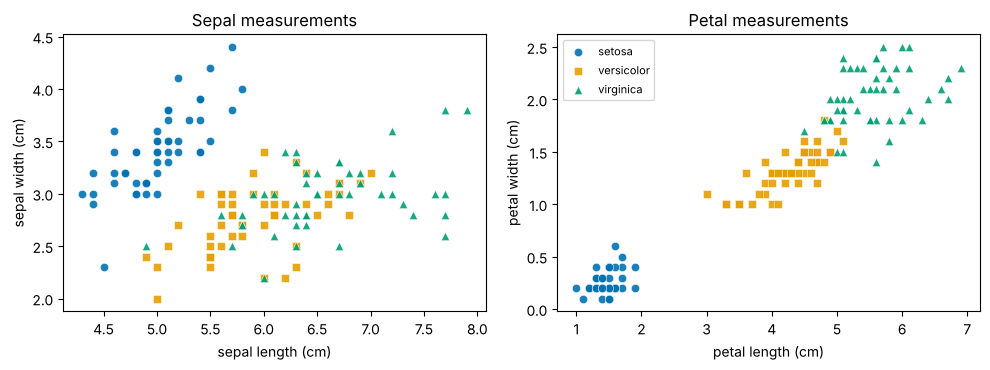

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
scatter_species(axes[0], df, "sepal length (cm)", "sepal width (cm)")
axes[0].set_title("Sepal measurements")
scatter_species(axes[1], df, "petal length (cm)", "petal width (cm)")
axes[1].set_title("Petal measurements")
axes[1].legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "01_two_views.png")
plt.show()

*Figure 2. What to notice:* in the petal view the three groups are almost separate clusters; in the sepal view two of the groups overlap a lot. KNN works well when similar flowers sit close together on the map, so a view with clear clusters makes its job easy.

## 6. Keep an exam set aside

If we test a model on the same flowers it remembered, KNN with `k=1` would look perfect for a silly reason: each flower is its own nearest neighbour. That is like grading a student with the exact questions they practised.

So we **split** the data: a *training set* the model may remember, and a *test set* it never sees until the final grade. We use 80% / 20% and a `stratify` option so each species keeps the same share in both parts.

In [10]:
x_train, x_test, y_train, y_test = split_data(df, test_size=0.2, seed=SEED)
print("train:", x_train.shape, " test:", x_test.shape)
print("species in the test set:")
print(y_test.value_counts())

train: (120, 4)  test: (30, 4)
species in the test set:
species
setosa        10
virginica     10
versicolor    10
Name: count, dtype: int64


Ten flowers of each species are in the test set, because we asked for a stratified split. The `seed` makes the split repeatable: run it again and you get the same 30 test flowers.

## 7. Our first KNN model

This is what my original 2022 script did: `k=1`, a single neighbour. **Predict first:** will it get everything right on the test set?

In [11]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=1)
model.fit(x_train, y_train)          # for KNN, "fit" just stores the training flowers
predictions = model.predict(x_test)

comparison = pd.DataFrame({"truth": y_test.to_numpy(), "prediction": predictions})
comparison.head(8)

,truth,prediction
0,setosa,setosa
1,virginica,virginica
2,versicolor,versicolor
3,versicolor,versicolor
4,setosa,setosa
5,versicolor,versicolor
6,setosa,setosa
7,setosa,setosa


In [12]:
wrong = comparison[comparison["truth"] != comparison["prediction"]]
print("test accuracy:", round(model.score(x_test, y_test), 3))
print("mistakes:", len(wrong), "out of", len(comparison))
wrong

test accuracy: 0.967
mistakes: 1 out of 30


,truth,prediction
19,virginica,versicolor


The accuracy is the fraction of test flowers named correctly. With seed 42 we get 29 right out of 30, and the single mistake is a *virginica* flower named *versicolor*: one of the two species that overlap in Figure 2.

## 8. The problem with one number

My original script had no seed and tested on only 15 flowers (10% of 150). Every run gave a different accuracy. Let us measure how much, by repeating that same experiment with 30 different random splits.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

X, y = df[FEATURES], df["species"]
accuracies = []
for split_seed in range(30):
    xa, xb, ya, yb = train_test_split(X, y, test_size=0.1, random_state=split_seed)
    accuracies.append(KNeighborsClassifier(n_neighbors=1).fit(xa, ya).score(xb, yb))

accuracies = np.array(accuracies)
print("lowest :", round(accuracies.min(), 3))
print("highest:", round(accuracies.max(), 3))
print("mean   :", round(accuracies.mean(), 3))
print("std    :", round(accuracies.std(), 3))

lowest : 0.8
highest: 1.0
mean   : 0.956
std    : 0.058


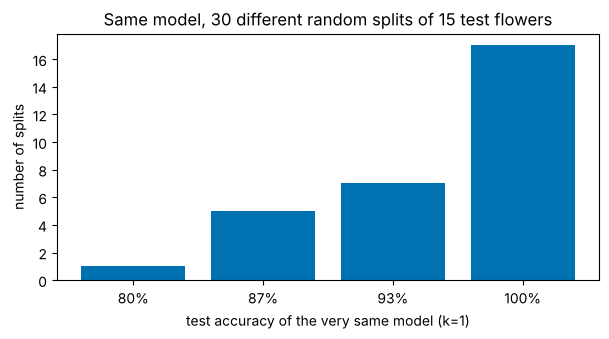

In [14]:
values, counts = np.unique(np.round(accuracies, 4), return_counts=True)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar([f"{v:.0%}" for v in values], counts, color="#0072B2")
ax.set_xlabel("test accuracy of the very same model (k=1)")
ax.set_ylabel("number of splits")
ax.yaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_title("Same model, 30 different random splits of 15 test flowers")
save_figure(fig, "01_accuracy_depends_on_split.png")
plt.show()

*Figure 3. What to notice:* the model never changed, only *which* 15 flowers were in the exam. In our 30 splits the score ranged from 80% to 100%. With so few test flowers one flower moves the score by 6.7 points (1 out of 15). A single number from a single split is a weak piece of evidence.

That is the question of notebook 02: how do we get a number we can trust, and how do we pick `k`?

## 9. Check yourself

**Question 1.** A new flower has 5 neighbours: 3 of species A and 2 of species B. What does KNN with `k=5` predict, and what would `k=1` predict if its single nearest neighbour is of species B?

<details>
<summary>Show the answer</summary>

With `k=5` the vote is 3 against 2, so it predicts **A**. With `k=1` only the closest neighbour counts, so it predicts **B**. Changing `k` can change the answer; that is why choosing `k` matters.

</details>

**Question 2.** Why do we not test the model on the same flowers it was trained on?

<details>
<summary>Show the answer</summary>

KNN stores the training flowers, so each one is its own nearest neighbour and `k=1` would look perfect. That tells us nothing about *new* flowers, which is what we care about.

</details>

**Question 3 (small exercise).** Change `seed=SEED` in the split of section 6 to `seed=7`, re-run sections 6 and 7, and compare the accuracy. Is it the same? Why?

<details>
<summary>Show the answer</summary>

It can change, because a different seed puts different flowers into the test set. The model is the same; the exam is different. This is exactly Figure 3.

</details>

## 10. Common mistakes

- **Testing on the training data.** Gives a flattering, meaningless score. Always keep a test set.
- **Trusting one split.** Section 8 showed that one split can mislead.
- **Forgetting the random seed.** Without it nobody (including you next week) can reproduce your result.
- **Ignoring class balance.** Here the classes are balanced; on other data a high accuracy can hide a useless model.

## 11. Recap

- KNN classifies a new example by letting its **K nearest labelled examples vote**; "nearest" usually means Euclidean distance.
- We evaluate on a **held-out test set** and fix a **random seed** so results are repeatable.
- One accuracy number from one small split can swing a lot, so we need a better way to measure.

**Next, in notebook 02:** how distance and feature scales matter, how to choose `k` with **cross-validation**, and how a decision boundary changes with `k`.

### Further reading
- scikit-learn user guide, *Nearest Neighbors*: https://scikit-learn.org/stable/modules/neighbors.html
- T. Cover and P. Hart (1967), *Nearest neighbor pattern classification*, IEEE Transactions on Information Theory 13(1), 21-27.
- R. A. Fisher (1936), *The use of multiple measurements in taxonomic problems*, Annals of Eugenics 7(2), 179-188.
- Iris data set, UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/53/iris